# Data Visualization using the Taxis Dataset

A visual analysis of taxi trips using Matplotlib, Pandas plot and Seaborn.

Prepared by: **Ansania Salam**

## ⚙️ Setup

Import the libraries used in this project.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Libraries imported")

Libraries imported


`pd`, `plt` and `sns` are the usual short names for Pandas, Matplotlib and Seaborn. The theme gives all charts a light grid, and the display options make sure the DataFrame shows every column when printed.


## 🚕 Step 1: Loading the Taxis Dataset

**1.1** Load the `taxis` dataset using Seaborn.

In [2]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

print("Shape:", df.shape)
print()
print(df.head())

Shape: (6433, 14)

               pickup             dropoff  passengers  distance  fare   tip  tolls  total   color      payment            pickup_zone           dropoff_zone pickup_borough dropoff_borough
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15    0.0  12.95  yellow  credit card        Lenox Hill West    UN/Turtle Bay South      Manhattan       Manhattan
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00    0.0   9.30  yellow         cash  Upper West Side South  Upper West Side South      Manhattan       Manhattan
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36    0.0  14.16  yellow  credit card          Alphabet City           West Village      Manhattan       Manhattan
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15    0.0  36.95  yellow  credit card              Hudson Sq         Yorkville West      Manhattan       Manhattan
4 2019-03-30 13:27:42 2019-03-30 13:37:14

`sns.load_dataset("taxis")` loads a built-in sample dataset into a DataFrame. It has 6,433 rows and 14 columns, with one row per taxi trip. The columns include pickup and dropoff times, distance, fare, tip, tolls, total, payment method and the pickup and dropoff zone and borough.


## 🧹 Step 2: Handling Missing Values

**2.1** Check for missing values in the dataset and identify columns with missing data.

In [3]:
missing = df.isnull().sum()

print("Missing values per column:")
print(missing[missing > 0])
print()
print("Rows with at least one missing value:", df.isnull().any(axis=1).sum())

Missing values per column:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Rows with at least one missing value: 92


`isnull().sum()` counts the empty cells in each column. Five columns have missing values: `payment` (44), `pickup_zone` (26), `dropoff_zone` (45), `pickup_borough` (26) and `dropoff_borough` (45). All of them are text columns. The numeric columns (distance, fare, tip, tolls and total) are complete.

**2.2** Impute missing values using appropriate strategies based on the column type (mean, median or mode for numerical columns, and mode for categorical columns).

In [4]:
# The columns with missing values are all categorical, so the mode (most frequent value) is used.
# The pickup columns are handled in the next step.
for col in ['payment', 'dropoff_zone', 'dropoff_borough']:
    df[col] = df[col].fillna(df[col].mode()[0])

missing = df.isnull().sum()
print("Missing values left:")
print(missing[missing > 0])

Missing values left:
pickup_zone       26
pickup_borough    26
dtype: int64


Mean and median only work for numbers, and there are no missing numbers here, so the mode is the right choice for the text columns. `payment` is filled with `credit card`, the most common method. `dropoff_zone` and `dropoff_borough` are filled with their most common values. These dropoff columns are not used in any chart, so this does not affect the results. Only the two pickup columns still have gaps.

**2.3** For columns that are critical and cannot be reasonably imputed, remove rows with missing values to maintain data integrity.

In [5]:
print("Rows before:", len(df))

# pickup_zone and pickup_borough are used to group and colour the charts, so a guessed value would be misleading
df = df.dropna(subset=['pickup_zone', 'pickup_borough'])

print("Rows after :", len(df))
print("Total missing values left:", df.isnull().sum().sum())

Rows before: 6433
Rows after : 6407
Total missing values left: 0


The pickup location is used to group and colour several charts, and it cannot be guessed. Filling it with the most common value would place trips in the wrong borough and change the results, so those 26 rows are removed. This is only about 0.4% of the data, and the zone and borough were missing on the same rows. The dataset is now complete, with 6,407 rows.


## 📊 Step 3: Visualizations using Matplotlib / Pandas Plot

**3.1 Line Chart:** Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

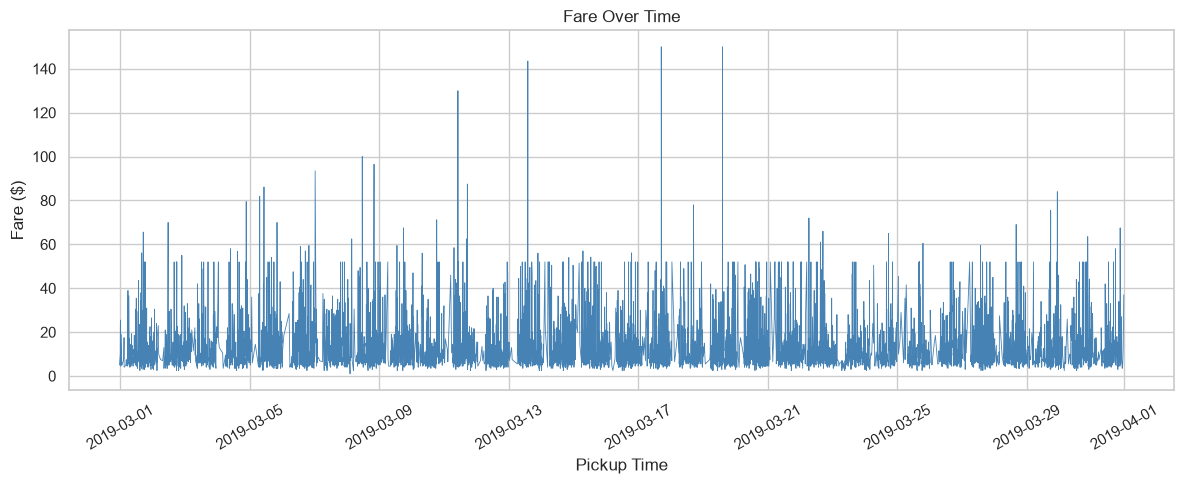

In [6]:
df['pickup'] = pd.to_datetime(df['pickup'])
df_time = df.sort_values('pickup')

plt.figure(figsize=(12, 5))
plt.plot(df_time['pickup'], df_time['fare'], linewidth=0.6, color='steelblue')
plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare ($)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

`pd.to_datetime()` makes sure the pickup column is a proper date and time. The rows are sorted by pickup time first, because a line chart joins points in the order they appear, and unsorted data would draw a tangled line. The line is spiky because every trip has its own fare. There is no clear rise or fall across the month, and most fares stay low, with occasional peaks from long trips.

**3.2 Bar Chart:** Create a bar chart to show the total fare for each `pickup_borough`. Group the data by `pickup_borough` and sum the fare for each group.

pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    58753.42
Queens       16382.06
Name: fare, dtype: float64


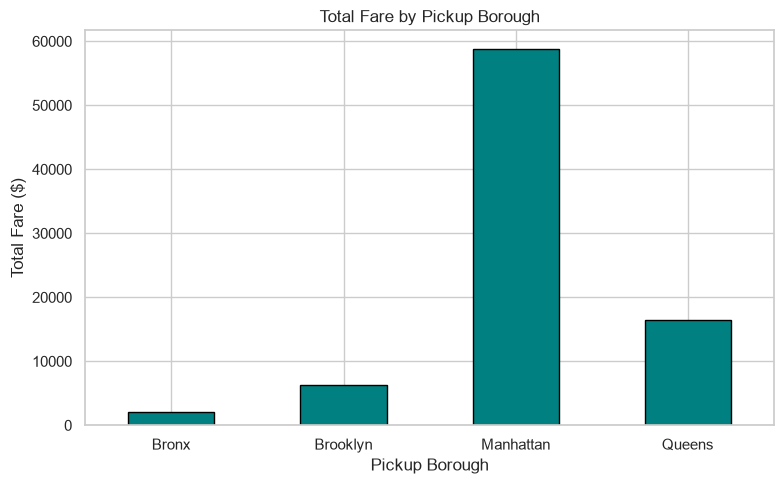

In [7]:
fare_by_borough = df.groupby('pickup_borough')['fare'].sum()
print(fare_by_borough.round(2))

fare_by_borough.plot(kind='bar', figsize=(8, 5), color='teal', edgecolor='black')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

`groupby()` splits the trips by borough, and `sum()` adds up the fares in each group. Manhattan brings in far more than the others, about $58.8K, followed by Queens (about $16.4K), Brooklyn (about $6.3K) and the Bronx (about $2.1K). This mostly follows how many trips start in each borough, as the count plot later shows.

**3.3 Pie Chart:** Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.). Each slice should represent the count of trips for a specific payment method.

payment
credit card    4600
cash           1807
Name: count, dtype: int64


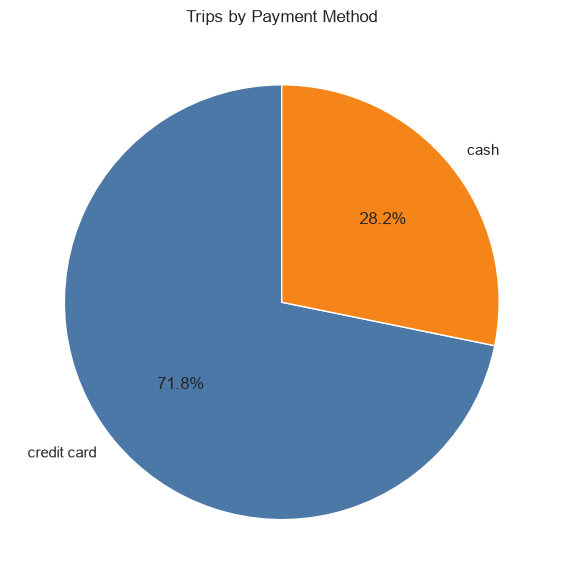

In [8]:
payment_counts = df['payment'].value_counts()
print(payment_counts)

payment_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90,
                    colors=['#4C78A8', '#F58518'], figsize=(6, 6),
                    wedgeprops={'edgecolor': 'white'})
plt.title('Trips by Payment Method')
plt.ylabel('')
plt.tight_layout()
plt.show()

`value_counts()` counts the trips for each payment method, and each slice of the pie is one count, with the percentage written on it. Credit card is the main method, used for roughly 72% of trips, and cash makes up the remaining 28%.

**3.4 Histogram:** Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.

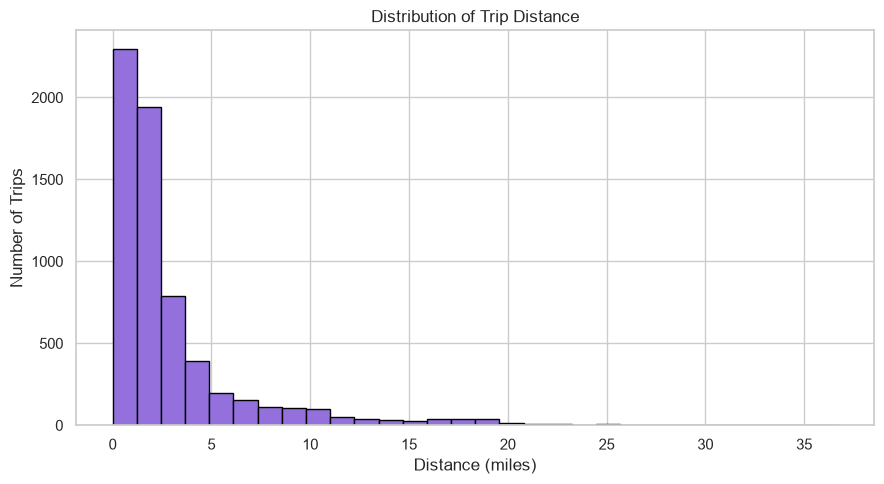

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(df['distance'], bins=30, color='mediumpurple', edgecolor='black')
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance (miles)')
plt.ylabel('Number of Trips')
plt.tight_layout()
plt.show()

A histogram groups the distances into bins and shows how many trips fall in each. With 30 bins, the shape is clear without the bars becoming too thin. The data is heavily skewed to the right: most trips are short (the median is about 1.65 miles) and the number of trips drops quickly as distance grows, with a long tail of rare trips up to about 36.7 miles.

**3.5 Box Plot:** Plot a box plot to visualize the distribution of tip amounts for each `pickup_borough`. Use `pickup_borough` as the categorical axis and `tip` as the numeric axis.

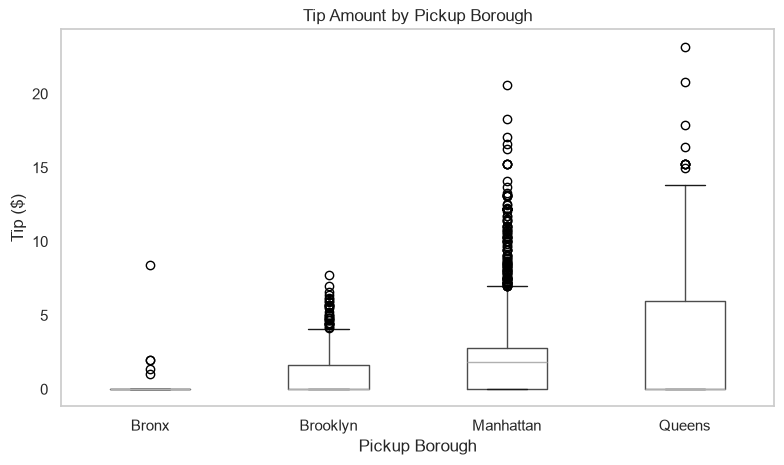

In [10]:
df.boxplot(column='tip', by='pickup_borough', figsize=(8, 5), grid=False)
plt.title('Tip Amount by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip ($)')
plt.tight_layout()
plt.show()

Each box shows the middle 50% of tips for a borough, the line inside is the median, and the dots are outliers. Manhattan has the highest median tip, about $1.86. In the Bronx, Brooklyn and Queens the median tip is 0, so most trips there have no recorded tip. Queens has the widest spread, though: the top quarter of its tips are above about $5.95. Every borough has outliers with much larger tips. Tips paid in cash are usually not recorded in taxi data like this, which may explain the many zeros.


## 🎨 Step 4: Visualizations using Seaborn

**4.1 Count Plot:** Create a count plot to visualize the number of trips in each `pickup_borough`. The x-axis should represent the boroughs, and the y-axis should show the count of trips.

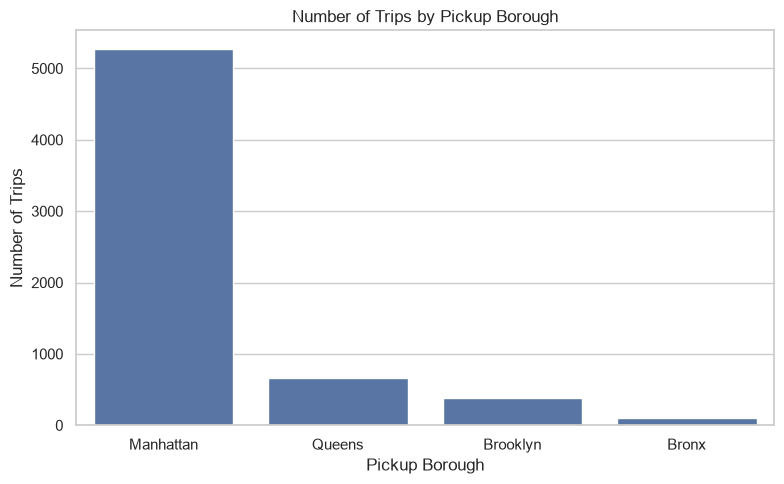

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='pickup_borough', order=df['pickup_borough'].value_counts().index)
plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.tight_layout()
plt.show()

`countplot()` counts the rows in each category and draws a bar for each one, so no grouping is needed beforehand. The boroughs are ordered from the most trips to the fewest. Manhattan has 5,268 trips, far ahead of Queens (657), Brooklyn (383) and the Bronx (99).

**4.2 Scatter Plot:** Plot a scatter plot to show the relationship between distance and fare. Use distance on the x-axis and fare on the y-axis, and color the points based on `pickup_borough`.

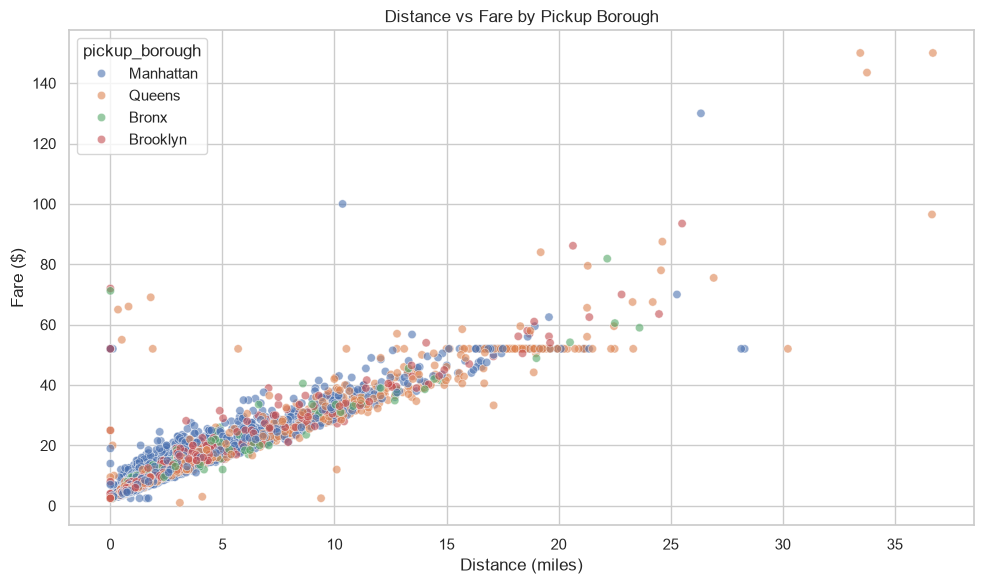

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough', alpha=0.6)
plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.tight_layout()
plt.show()

Fare rises steadily with distance, and the points sit close to a straight line (the correlation is about 0.94). The `hue` setting colours each trip by its pickup borough. Most of the points in the short-distance cluster are Manhattan trips, as Manhattan has by far the most trips, while Queens trips tend to be longer. A flat row of points at exactly $52 stands out (129 trips, mostly long ones), which looks like a fixed fare rather than a metered one. A handful of trips show zero distance but a high fare, which may be recording errors.

**4.3 Heatmap:** Plot a heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the relationships.

          distance  fare   tip  tolls  total
distance      1.00  0.94  0.46   0.64   0.92
fare          0.94  1.00  0.47   0.61   0.97
tip           0.46  0.47  1.00   0.41   0.63
tolls         0.64  0.61  0.41   1.00   0.68
total         0.92  0.97  0.63   0.68   1.00


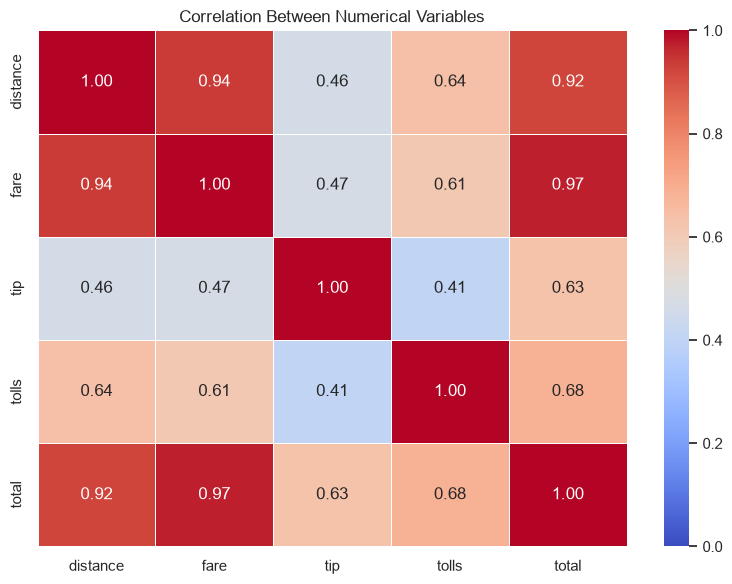

In [13]:
corr = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()
print(corr.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=1, linewidths=0.5)
plt.title('Correlation Between Numerical Variables')
plt.tight_layout()
plt.show()

`corr()` gives a correlation between every pair of columns, from 0 (no relationship) to 1 (a perfect rise together), and the heatmap colours them so strong links stand out. Fare, total and distance are strongly linked: fare and total 0.97, distance and fare 0.94, and distance and total 0.92. Tolls have a moderate link with distance (0.64). Tip has the weakest links, between 0.41 and 0.63.

**4.4 Pair Plot:** Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total. Color the data points according to `pickup_zone` to compare how different zones affect these variables.

Top 5 pickup zones: ['Midtown Center', 'Upper East Side South', 'Penn Station/Madison Sq West', 'Clinton East', 'Midtown East']
Trips in these zones: 1057


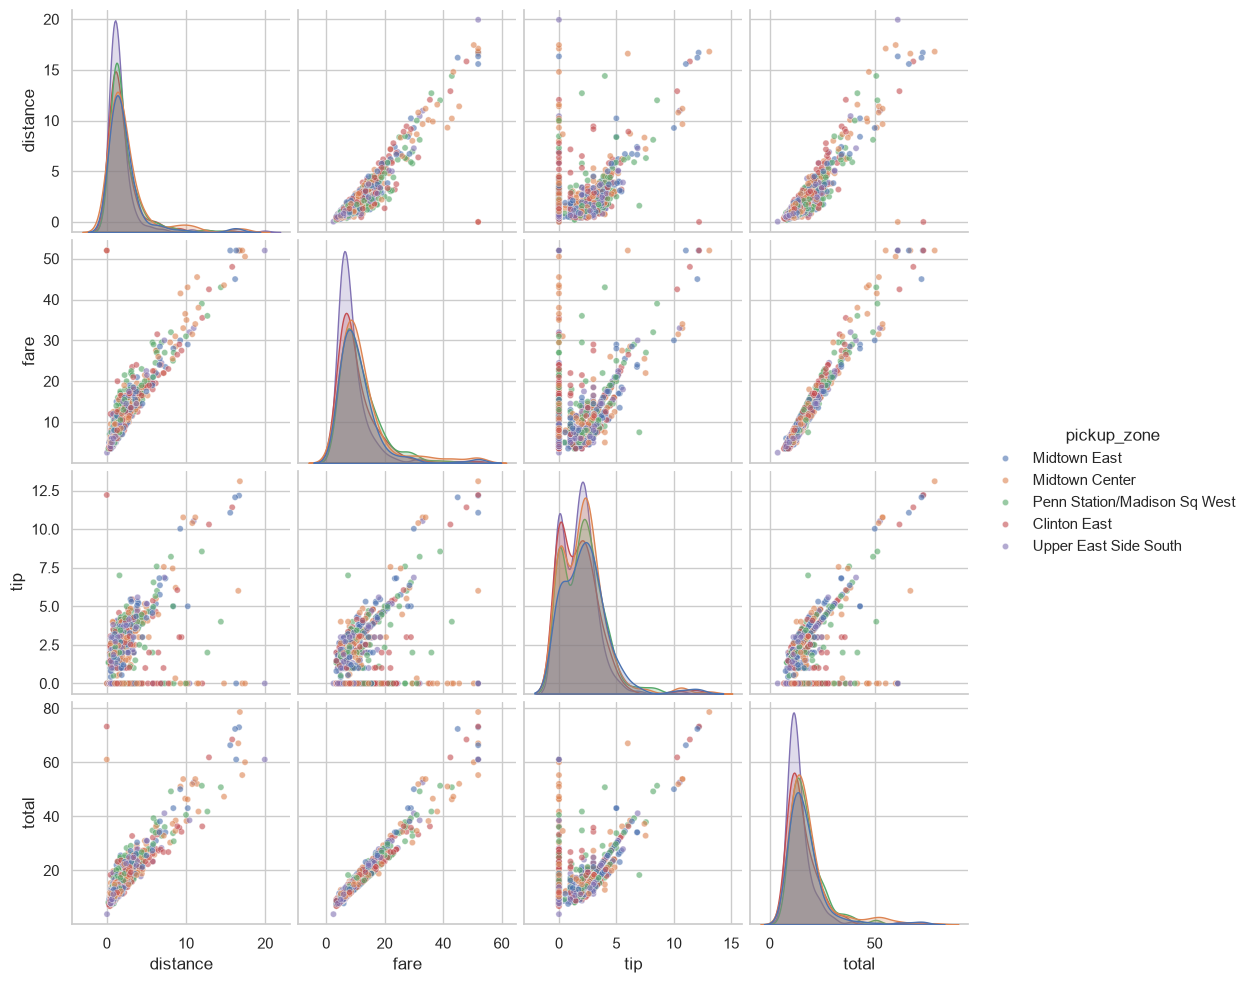

In [14]:
# The dataset has 194 pickup zones, which is too many to colour separately, so the 5 busiest zones are used
top_zones = df['pickup_zone'].value_counts().head(5).index
df_top = df[df['pickup_zone'].isin(top_zones)]

print("Top 5 pickup zones:", list(top_zones))
print("Trips in these zones:", len(df_top))

sns.pairplot(df_top, vars=['distance', 'fare', 'tip', 'total'], hue='pickup_zone',
             plot_kws={'alpha': 0.6, 's': 20})
plt.show()

A pair plot draws a scatter plot for every pair of variables, with the distribution of each variable on the diagonal. Colouring by `pickup_zone` with all 194 zones would give an unreadable legend, so only the five busiest zones are used. Distance, fare and total form tight upward lines for every zone, meaning they move together. Tip is much more scattered, with many trips at zero tip.

**4.5 Violin Plot:** Plot a violin plot to show the distribution of fare for each payment method. Use the payment method as the categorical axis and fare as the numeric axis.

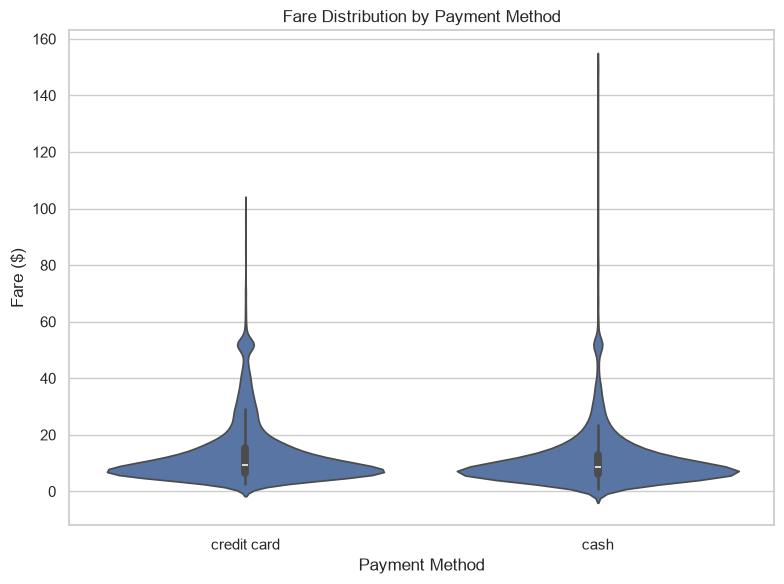

In [15]:
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x='payment', y='fare')
plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')
plt.tight_layout()
plt.show()

A violin plot shows the shape of the data: the wider the violin, the more trips at that fare. Both payment methods are widest at low fares, with a long thin tail towards higher fares. The typical fare is similar, slightly higher for credit card (a median of about 9.50 dollars, against 8.50 dollars for cash). The most expensive trip, 150 dollars, was paid in cash. The violins dip slightly below zero only because of smoothing, since the lowest fare in the data is 1 dollar.